# Extended Data Figure 4. Sensitivity of simulated TCN responses to chromosomal lower-boundary assumptions

In [1]:
OUTPUT_NAME="Extended_data_figure_4_boundary"
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.environ.setdefault("SIM_RUN_MODE", "production")
%run ./simulation_core.ipynb
plt.rcParams.update(PLOT_STYLE)
OUTPUT_ROOT, FIGURE_DIR, SOURCE_DIR = make_output_dirs(OUTPUT_NAME)
MAX_PCN_TEST = 100
PRIMARY = {c.condition: c for c in standard_configurations(MAX_PCN_TEST)}

def baseline_check():
    # Confirm shared Figure 2 coefficients and that we have not mutated them.
    assert np.isclose(PRIMARY["transposition off"].kappa_f, TRANSITIONS.kappa_f_off)
    assert np.isclose(PRIMARY["transposition on"].kappa_b, TRANSITIONS.kappa_b_on)
    assert np.isclose(PRIMARY["transposition on + PCN dynamics"].kappa_f, TRANSITIONS.kappa_f_pcn)
    assert CONSECUTIVE_CONVERGED_CYCLES == 8
    assert MIN_CONVERGENCE_CYCLES == 60
    assert RELAXED_DAYS_PER_CYCLE == 5 and SELECTED_DAYS_PER_CYCLE == 2
    assert np.isclose(PASSAGE_DILUTION_FACTOR, 30000)

baseline_check()
print("Core and Figure 4 configuration checks passed; mode:", RUN_MODE)
BOUNDARY_CONDITIONS = ("transposition off", "transposition on")
BOUNDARY_VARIANTS = {
    "primary boundary": {"lower_forward_rate": float(TRANSITIONS.lower_forward_rate), "chromosomal_copy": 1},
    "restricted boundary": {"lower_forward_rate": 0.0, "chromosomal_copy": 1},
    "TCN = 0 allowed": {"lower_forward_rate": 0.0, "chromosomal_copy": 0},
}
VARIANT_STYLES = {"primary boundary": "-", "restricted boundary": "--", "TCN = 0 allowed": ":"}
configs = {}
for condition in BOUNDARY_CONDITIONS:
    base = PRIMARY[condition]
    for variant, settings in BOUNDARY_VARIANTS.items():
        configs[(condition, variant)] = make_configuration(
            MAX_PCN_TEST, condition=condition, kappa_f=base.kappa_f,
            kappa_b=base.kappa_b, lower_forward_rate=settings["lower_forward_rate"],
            setting_label=f"R1 boundary: {variant}")
        assert_generator_valid(transition_matrix(MAX_PCN_TEST, configs[(condition, variant)]))
for condition in BOUNDARY_CONDITIONS:
    a = transition_matrix(MAX_PCN_TEST, configs[(condition, "primary boundary")])
    b = transition_matrix(MAX_PCN_TEST, configs[(condition, "restricted boundary")])
    z = transition_matrix(MAX_PCN_TEST, configs[(condition, "TCN = 0 allowed")])
    changed = np.argwhere(np.abs(a-b)>1e-12)
    assert set(map(tuple, changed)) == {(0,0),(1,0)}
    assert np.array_equal(b,z)
assert total_tcn_states(MAX_PCN_TEST,chromosomal_copy=0)[0] == 0
assert total_tcn_states(MAX_PCN_TEST,chromosomal_copy=1)[0] == 1
print("Boundary generators and chromosome-free state mapping validated.")
fixed_rows=[]; fixed_frames=[]
for (condition, variant), cfg in configs.items():
    chromosomal_copy = BOUNDARY_VARIANTS[variant]["chromosomal_copy"]
    for phase, duration, initial in (
        ("loss", RELAXED_DAYS_PER_CYCLE, fixed_loss_initial_state(MAX_PCN_TEST)),
        ("gain", SELECTED_DAYS_PER_CYCLE, fixed_gain_initial_state(MAX_PCN_TEST)),
    ):
        # Preserve identical initial abundance weights across the three state interpretations.
        traj, daily, state, summary = simulate_phase(
            MAX_PCN_TEST, cfg, phase=phase, duration_days=duration,
            initial_state=initial.copy(), record_trajectory=True,
            chromosomal_copy=chromosomal_copy)
        traj=traj.copy(); traj["variant"]=variant; traj["condition"]=condition; traj["phase"]=phase
        fixed_frames.append(traj)
        fixed_rows.append({"condition":condition,"variant":variant,"chromosomal_copy":chromosomal_copy,
                           "phase":phase,"endpoint_TCN":summary["final_TCN"]})
fixed=pd.concat(fixed_frames,ignore_index=True)
fixed_summary=pd.DataFrame(fixed_rows)
periodic_rows=[]; periodic_frames=[]
for (condition,variant),cfg in configs.items():
    chromosomal_copy=BOUNDARY_VARIANTS[variant]["chromosomal_copy"]
    # The same initial abundance vector is used in all variants.
    init=periodic_initial_state(MAX_PCN_TEST)
    conv=converge_periodic_state(MAX_PCN_TEST,cfg,init,chromosomal_copy=chromosomal_copy)
    row={"condition":condition,"variant":variant,"chromosomal_copy":chromosomal_copy,
         "converged":bool(conv["converged"]),"cycles_to_convergence":conv["cycles_to_convergence"],
         "TCN_low":conv["TCN_low"],"TCN_high":conv["TCN_high"]}
    row.update(periodic_metrics(conv["TCN_low"],conv["TCN_high"],conv["minimum_daily_prepassage_density"],
                                converged=conv["converged"],population_extinct=conv["population_extinct"]))
    periodic_rows.append(row)
    if conv["converged"]:
        traj, post=simulate_post_convergence_cycles(MAX_PCN_TEST,cfg,conv["state"],chromosomal_copy=chromosomal_copy)
        traj=traj.copy();traj["variant"]=variant;traj["condition"]=condition
        periodic_frames.append(traj)
periodic_summary=pd.DataFrame(periodic_rows)
print(periodic_summary[["condition","variant","converged","response_valid","TCN_low","TCN_high","loss_rate","gain_rate"]].to_string(index=False))


Core and Figure 4 configuration checks passed; mode: production
Boundary generators and chromosome-free state mapping validated.
        condition             variant  converged  response_valid  TCN_low  TCN_high  loss_rate  gain_rate
transposition off    primary boundary       True            True 9.374755 40.112394   0.019548   0.048870
transposition off restricted boundary       True            True 7.559396 40.340701   0.022519   0.056297
transposition off     TCN = 0 allowed       True            True 3.868388 41.585907   0.031937   0.079842
 transposition on    primary boundary       True            True 3.138889 48.480516   0.036810   0.092024
 transposition on restricted boundary       True            True 2.732274 48.660822   0.038725   0.096813
 transposition on     TCN = 0 allowed       True            True 1.055402 50.011760   0.051885   0.129712


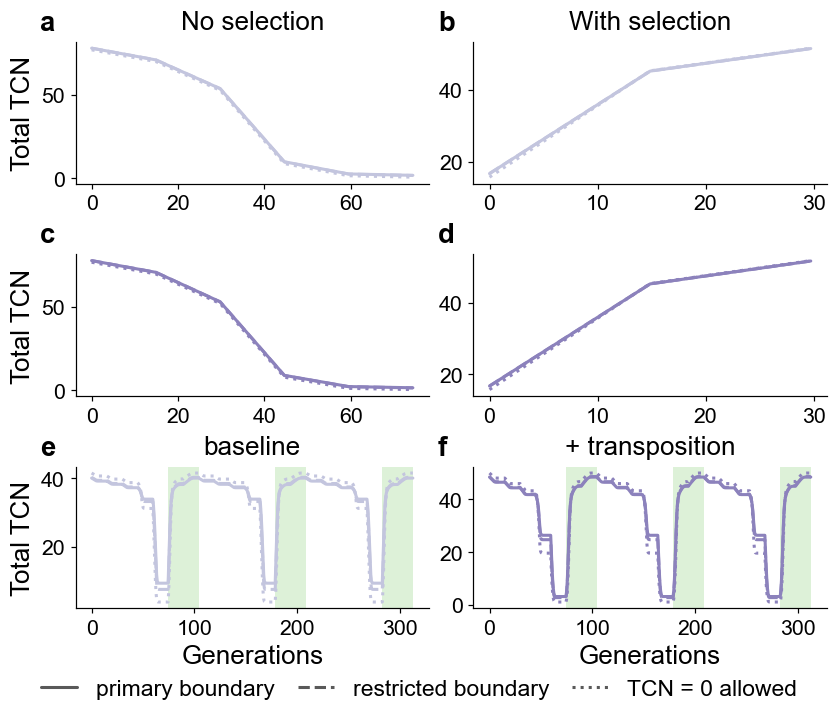

In [2]:

from matplotlib.lines import Line2D

fig, axs = plt.subplots(
    3, 2,
    figsize=(7.5, 6.5),
    constrained_layout=True
)

variants = tuple(BOUNDARY_VARIANTS)

for ri, condition in enumerate(BOUNDARY_CONDITIONS):
    for ci, phase in enumerate(("loss", "gain")):
        ax = axs[ri, ci]

        for variant in variants:
            d = fixed.loc[
                (fixed["condition"] == condition)
                & (fixed["variant"] == variant)
                & (fixed["phase"] == phase)
            ]

            v = (
                d.loc[
                    d["passage_status"].isin(["phase_start", "pre_passage"])
                ]
                .drop_duplicates("phase_day", keep="last")
            )

            ax.plot(
                v["phase_day"] * PASSAGE_GENERATIONS,
                v["TCN_per_density"],
                color=CONDITION_COLORS[condition],
                ls=VARIANT_STYLES[variant],
                lw=2
            )

        if ri == 0:
            ax.set_title(
                "No selection" if ci == 0 else "With selection",
                fontsize=17,
                pad=8
            )

        ax.text(
            -0.10, 1.04,
            "abcd"[ri * 2 + ci],
            transform=ax.transAxes,
            fontsize=18,
            fontweight="bold",
            va="bottom"
        )

        ax.tick_params(labelsize=14)

        if ci == 0:
            ax.set_ylabel("Total TCN", fontsize=17)


for ci, condition in enumerate(BOUNDARY_CONDITIONS):
    ax = axs[2, ci]

    for cycle in range(
        1, ADDITIONAL_CYCLES_AFTER_CONVERGENCE + 1
    ):
        left = (
            (cycle - 1) * DAYS_PER_CYCLE
            + RELAXED_DAYS_PER_CYCLE
        ) * PASSAGE_GENERATIONS

        right = (
            cycle * DAYS_PER_CYCLE
            * PASSAGE_GENERATIONS
        )

        ax.axvspan(
            left, right,
            color=SELECTION_SHADE,
            lw=0,
            zorder=0
        )

    for variant in variants:
        frames = [
            d for d in periodic_frames
            if d["condition"].iloc[0] == condition
            and d["variant"].iloc[0] == variant
        ]

        if frames:
            d = frames[0]

            ax.plot(
                d["Day"] * PASSAGE_GENERATIONS,
                d["TCN_per_density"],
                color=CONDITION_COLORS[condition],
                ls=VARIANT_STYLES[variant],
                lw=2
            )

    ax.set_title(
        DISPLAY_LABELS[condition],
        fontsize=17,
        pad=8
    )

    ax.text(
        -0.10, 1.04,
        "ef"[ci],
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="bottom"
    )

    ax.set_xlabel("Generations", fontsize=17)
    ax.tick_params(labelsize=14)

    if ci == 0:
        ax.set_ylabel("Total TCN", fontsize=17)


handles = [
    Line2D(
        [0], [0],
        color="0.35",
        ls=VARIANT_STYLES[v],
        lw=2,
        label=v
    )
    for v in variants
]

fig.legend(
    handles=handles,
    loc="outside lower center",
    ncol=3,
    frameon=False,
    fontsize=15,
    handlelength=1.6,
    columnspacing=1.0
)

save_figure(
    fig,
    "Extended_data_figure_4_boundary_sensitivity_multipanel",
    FIGURE_DIR
)

plt.show()
